# Install Requirements

In [2]:
!pip install numpy pandas scikit-learn torch

In [3]:
!pip install torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 12.3 MB/s eta 0:00:00


# Start Coding for CMaps dataset

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
from torch.utils.data import Dataset


## Connect to Drive

In [5]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Data loading (unchanged)
index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['sensor_{}'.format(i+1) for i in range(0,21)]
col_names = index_names + setting_names + sensor_names

base_path = '/content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/'

dftrain = pd.read_csv(base_path + 'train_FD001.txt', sep='\s+', header=None, index_col=False, names=col_names)
dfvalid = pd.read_csv(base_path + 'test_FD001.txt', sep='\s+', header=None, index_col=False, names=col_names)
y_valid = pd.read_csv(base_path + 'RUL_FD001.txt', sep='\s+', header=None, index_col=False, names=['RUL'])

dfvalid.shape


<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1691940810.py:9: SyntaxWarning: invalid escape sequence '\s'
  dftrain = pd.read_csv(base_path + 'train_FD001.txt', sep='\s+', header=None, index_col=False, names=col_names)
/tmp/ipython-input-1691940810.py:10: SyntaxWarning: invalid escape sequence '\s'
  dfvalid = pd.read_csv(base_path + 'test_FD001.txt', sep='\s+', header=None, index_col=False, names=col_names)
/tmp/ipython-input-1691940810.py:11: SyntaxWarning: invalid escape sequence '\s'
  y_valid = pd.read_csv(base_path + 'RUL_FD001.txt', sep='\s+', header=None, index_col=False, names=['RUL'])


(13096, 26)

In [7]:
train = dftrain.copy()
valid = dfvalid.copy()


In [8]:
display(train)

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [9]:
print('Shape of the train dataset : ',train.shape)
print('Shape of the validation dataset : ',valid.shape)
print('Percentage of the validation dataset : ',len(valid)/(len(valid)+len(train)))

Shape of the train dataset :  (20631, 26)
Shape of the validation dataset :  (13096, 26)
Percentage of the validation dataset :  0.3882942449669404


In [10]:
train.loc[:,['unit_number','time_cycles']].describe()


,unit_number,time_cycles
count,20631.000000,20631.000000
mean,51.506568,108.807862
std,29.227633,68.880990
min,1.000000,1.000000
25%,26.000000,52.000000
50%,52.000000,104.000000
75%,77.000000,156.000000
max,100.000000,362.000000


In [11]:
train.loc[:,'sensor_1':].describe().transpose()


,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,4.660829e-13,1.3000,1.3000,1.3000,1.3000,1.3000


## Maximum time cycle of each unit

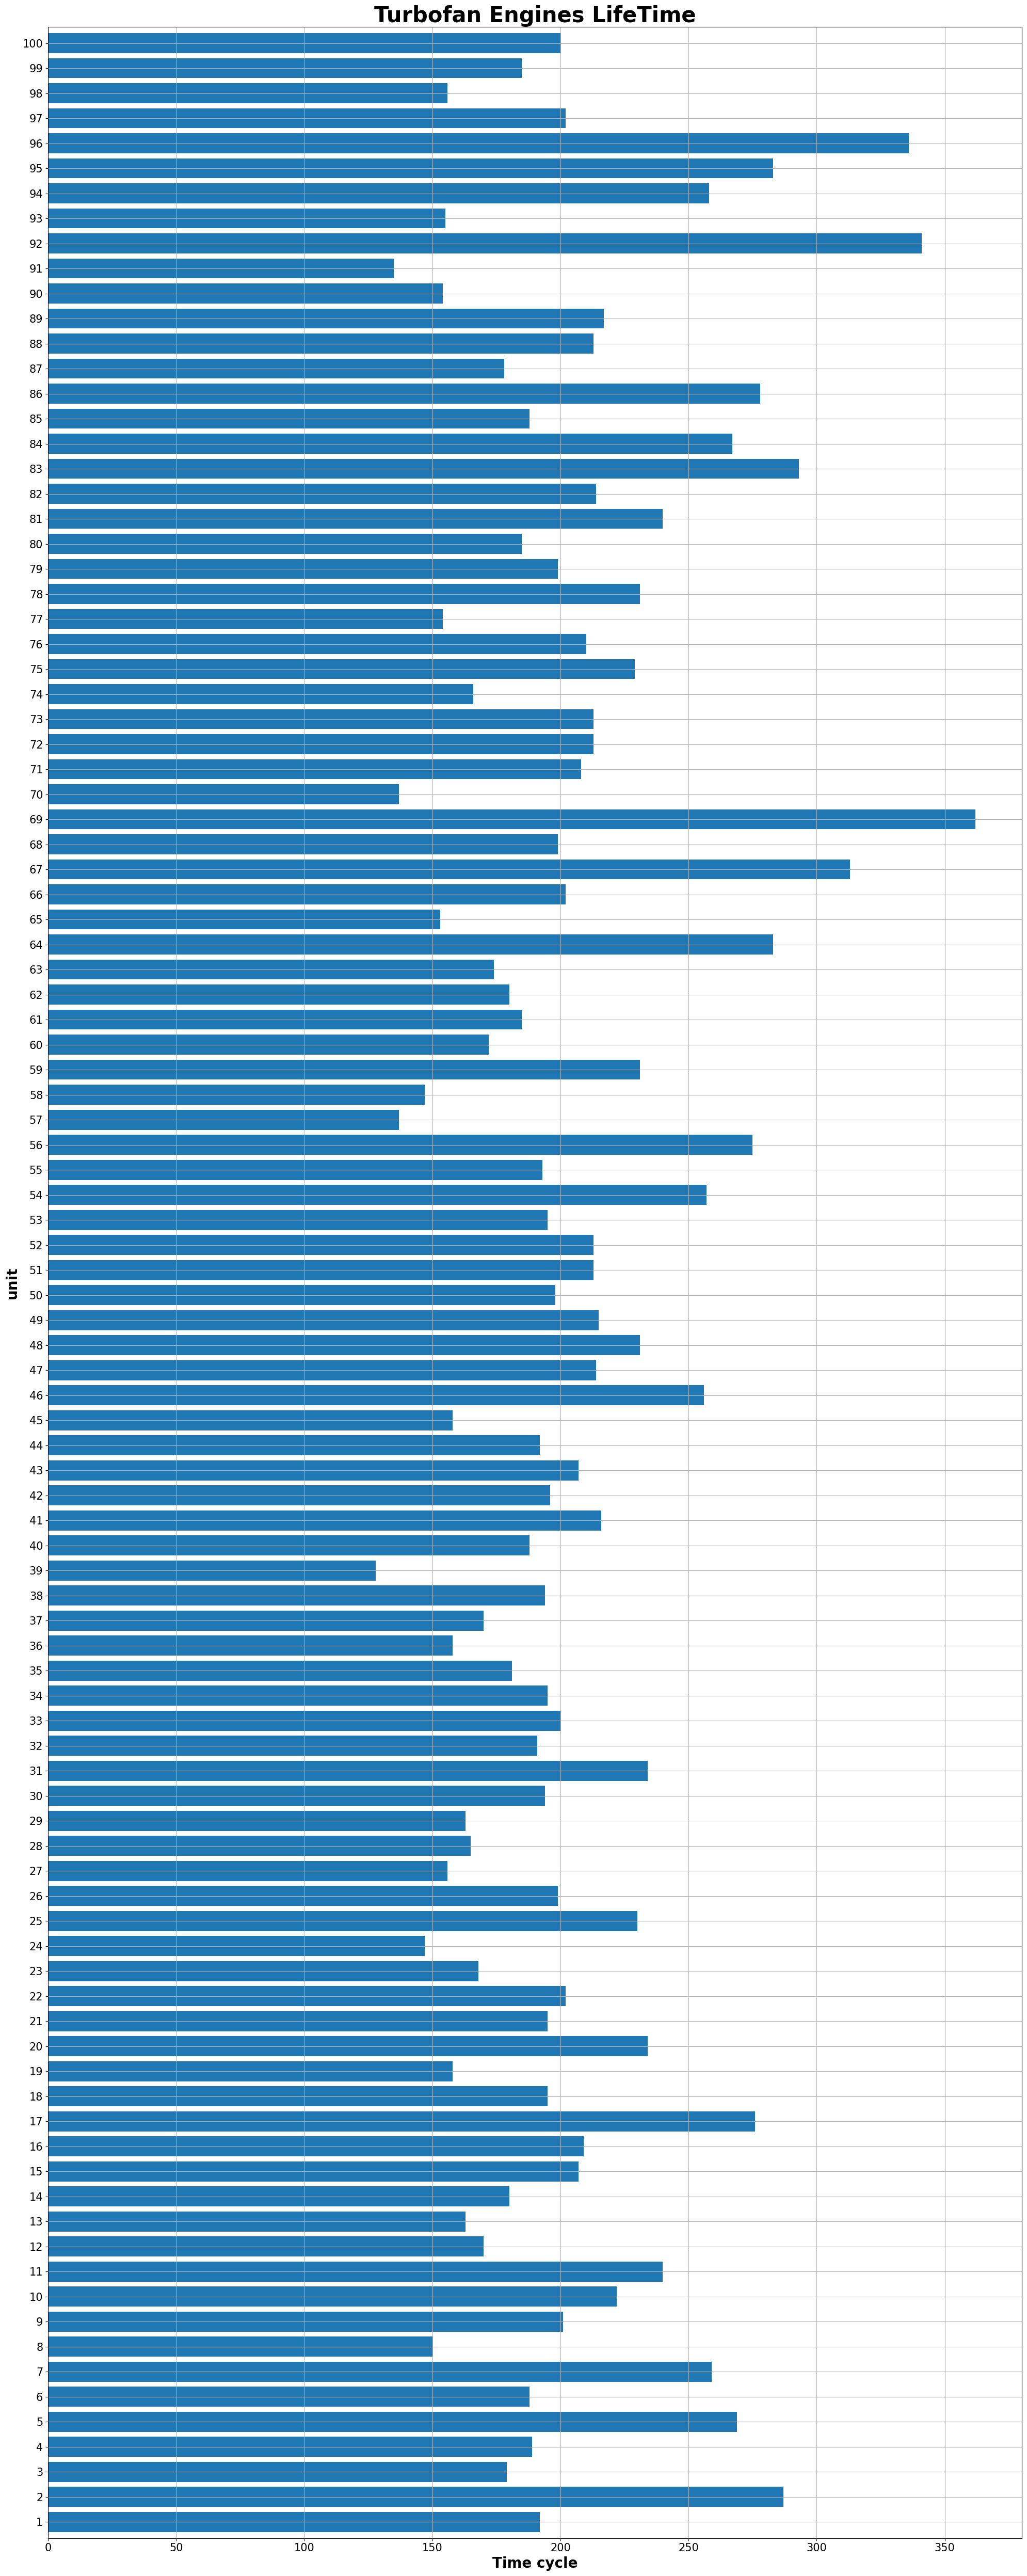

In [12]:
max_time_cycles=train[index_names].groupby('unit_number').max()
plt.figure(figsize=(20,50))
ax=max_time_cycles['time_cycles'].plot(kind='barh',width=0.8, stacked=True,align='center')
plt.title('Turbofan Engines LifeTime',fontweight='bold',size=30)
plt.xlabel('Time cycle',fontweight='bold',size=20)
plt.xticks(size=15)
plt.ylabel('unit',fontweight='bold',size=20)
plt.yticks(size=15)
plt.grid(True)
plt.tight_layout()
plt.show()

Text(0.5, 9.444444444444459, 'max time cycle')

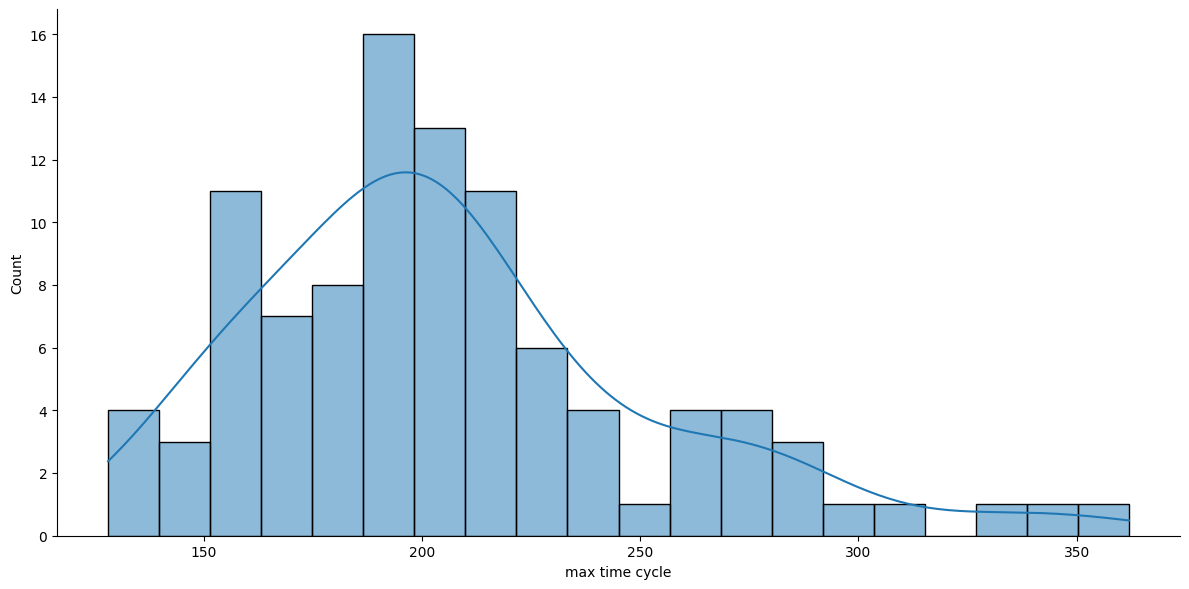

In [13]:
#Distribution of maximum time cycles
sns.displot(max_time_cycles['time_cycles'],kde=True,bins=20,height=6,aspect=2)
plt.xlabel('max time cycle')

In [14]:
# Add RUL to train
train_grouped = train.groupby('unit_number')
rul = []
for name, group in train_grouped:
    max_cycle = group['time_cycles'].max()
    rul_unit = max_cycle - group['time_cycles']
    rul.extend(rul_unit)
train['RUL'] = rul
train['RUL'] = np.minimum(train['RUL'], 125)


In [ ]:
train


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,1


In [15]:
# Add RUL to valid (Fixed merging)
y_valid['unit_number'] = range(1, len(y_valid) + 1)  # Add unit_number column to y_valid
valid_grouped = valid.groupby('unit_number')
valid_max_cycles = valid_grouped['time_cycles'].max().reset_index()
valid = valid.merge(valid_max_cycles, on='unit_number', suffixes=('', '_max'))
valid['RUL_temp'] = valid['time_cycles_max'] - valid['time_cycles']
valid['RUL_temp'] = np.minimum(valid['RUL_temp'], 125)
valid = valid.merge(y_valid, on='unit_number', how='left')
valid['RUL'] = valid['RUL_temp'] + valid['RUL']
valid = valid.drop(['RUL_temp', 'time_cycles_max'], axis=1)
valid['RUL'] = valid['RUL'].fillna(0)  # Fill any remaining NaN


In [16]:
train[['unit_number','RUL']]


,unit_number,RUL
0,1,125
1,1,125
2,1,125
3,1,125
4,1,125
...,...,...
20626,100,4
20627,100,3
20628,100,2
20629,100,1


In [17]:
valid

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,142
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,141
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,140
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,139
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974,24
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771,23
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051,22
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699,21


In [18]:

# Data Validation
print("NaN in valid['RUL']:", valid['RUL'].isna().sum())
print("Inf in valid['RUL']:", np.isinf(valid['RUL']).sum())
print("NaN in train['RUL']:", train['RUL'].isna().sum())
print("Inf in train['RUL']:", np.isinf(train['RUL']).sum())

train = train.dropna()
valid = valid.dropna()
train = train[~train.isin([np.inf, -np.inf]).any(axis=1)]
valid = valid[~valid.isin([np.inf, -np.inf]).any(axis=1)]

NaN in valid['RUL']: 0
Inf in valid['RUL']: 0
NaN in train['RUL']: 0
Inf in train['RUL']: 0


In [ ]:
valid

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,142.0
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,127.0
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,97.0
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,109.0
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,117.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974,NaN
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771,NaN
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051,NaN
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699,NaN


In [19]:
# Select sensors
constant_sensors = ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
selected_sensors = [s for s in sensor_names if s not in constant_sensors]
features = setting_names + selected_sensors

In [20]:
# Normalize
scaler = MinMaxScaler()
train[features] = scaler.fit_transform(train[features])
valid[features] = scaler.transform(valid[features])

In [21]:
train


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.459770,0.166667,0.0,518.67,0.183735,0.406802,0.309757,14.62,...,0.205882,0.199608,0.363986,0.03,0.333333,2388,100.0,0.713178,0.724662,125
1,1,2,0.609195,0.250000,0.0,518.67,0.283133,0.453019,0.352633,14.62,...,0.279412,0.162813,0.411312,0.03,0.333333,2388,100.0,0.666667,0.731014,125
2,1,3,0.252874,0.750000,0.0,518.67,0.343373,0.369523,0.370527,14.62,...,0.220588,0.171793,0.357445,0.03,0.166667,2388,100.0,0.627907,0.621375,125
3,1,4,0.540230,0.500000,0.0,518.67,0.343373,0.256159,0.331195,14.62,...,0.294118,0.174889,0.166603,0.03,0.333333,2388,100.0,0.573643,0.662386,125
4,1,5,0.390805,0.333333,0.0,518.67,0.349398,0.257467,0.404625,14.62,...,0.235294,0.174734,0.402078,0.03,0.416667,2388,100.0,0.589147,0.704502,125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,0.477011,0.250000,0.0,518.67,0.686747,0.587312,0.782917,14.62,...,0.558824,0.194344,0.656791,0.03,0.750000,2388,100.0,0.271318,0.109500,4
20627,100,197,0.408046,0.083333,0.0,518.67,0.701807,0.729453,0.866475,14.62,...,0.500000,0.188668,0.727203,0.03,0.583333,2388,100.0,0.124031,0.366197,3
20628,100,198,0.522989,0.500000,0.0,518.67,0.665663,0.684979,0.775321,14.62,...,0.529412,0.212148,0.922278,0.03,0.833333,2388,100.0,0.232558,0.053991,2
20629,100,199,0.436782,0.750000,0.0,518.67,0.608434,0.746021,0.747468,14.62,...,0.514706,0.203065,0.823394,0.03,0.583333,2388,100.0,0.116279,0.234466,1


In [ ]:
# Normalize RUL
# rul_scaler = MinMaxScaler()
# train['RUL'] = rul_scaler.fit_transform(train[['RUL']])
# valid['RUL'] = rul_scaler.transform(valid[['RUL']])

In [ ]:
valid

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,cycle_RUL,RUL
0,1,1,0.632184,0.750000,0.0,518.67,0.545181,0.310661,0.269413,14.62,...,0.132160,0.308965,0.03,0.333333,2388,100.0,0.558140,0.661834,30,0.896
1,1,2,0.344828,0.250000,0.0,518.67,0.150602,0.379551,0.222316,14.62,...,0.204768,0.213159,0.03,0.416667,2388,100.0,0.682171,0.686827,29,0.896
2,1,3,0.517241,0.583333,0.0,518.67,0.376506,0.346632,0.322248,14.62,...,0.155640,0.458638,0.03,0.416667,2388,100.0,0.728682,0.721348,28,0.896
3,1,4,0.741379,0.500000,0.0,518.67,0.370482,0.285154,0.408001,14.62,...,0.170090,0.257022,0.03,0.250000,2388,100.0,0.666667,0.662110,27,0.896
4,1,5,0.580460,0.500000,0.0,518.67,0.391566,0.352082,0.332039,14.62,...,0.152751,0.300885,0.03,0.166667,2388,100.0,0.658915,0.716377,26,0.896
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.781609,0.500000,0.0,518.67,0.611446,0.619359,0.566172,14.62,...,0.584890,0.564063,0.03,0.500000,2388,100.0,0.395349,0.418669,4,0.160
13092,100,195,0.436782,0.416667,0.0,518.67,0.605422,0.537388,0.671843,14.62,...,0.572350,0.485956,0.03,0.583333,2388,100.0,0.333333,0.528721,3,0.160
13093,100,196,0.465517,0.250000,0.0,518.67,0.671687,0.482014,0.414754,14.62,...,0.605326,0.507888,0.03,0.583333,2388,100.0,0.372093,0.429301,2,0.160
13094,100,197,0.281609,0.583333,0.0,518.67,0.617470,0.522128,0.626435,14.62,...,0.622046,0.562524,0.03,0.583333,2388,100.0,0.403101,0.518779,1,0.160


In [22]:
# Enhanced Feature Engineering: Add sensor statistics
def add_sensor_stats(df, sensors, window_size):
    df = df.copy()
    for sensor in sensors:
        df[f'{sensor}_mean'] = df.groupby('unit_number')[sensor].rolling(window=window_size, min_periods=1).mean().reset_index(level=0, drop=True).fillna(0)
        df[f'{sensor}_std'] = df.groupby('unit_number')[sensor].rolling(window=window_size, min_periods=1).std().reset_index(level=0, drop=True).fillna(0)
    return df

In [23]:
window_size = 20
train = add_sensor_stats(train, selected_sensors, window_size)
valid = add_sensor_stats(valid, selected_sensors, window_size)



In [ ]:
train

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14_mean,sensor_14_std,sensor_15_mean,sensor_15_std,sensor_17_mean,sensor_17_std,sensor_20_mean,sensor_20_std,sensor_21_mean,sensor_21_std
0,1,1,0.459770,0.166667,0.0,518.67,0.183735,0.406802,0.309757,14.62,...,0.199608,0.000000,0.363986,0.000000,0.333333,0.000000,0.713178,0.000000,0.724662,0.000000
1,1,2,0.609195,0.250000,0.0,518.67,0.283133,0.453019,0.352633,14.62,...,0.181211,0.026018,0.387649,0.033464,0.333333,0.000000,0.689922,0.032889,0.727838,0.004491
2,1,3,0.252874,0.750000,0.0,518.67,0.343373,0.369523,0.370527,14.62,...,0.178071,0.019184,0.377581,0.029394,0.277778,0.096225,0.669251,0.042694,0.692350,0.061548
3,1,4,0.540230,0.500000,0.0,518.67,0.343373,0.256159,0.331195,14.62,...,0.177276,0.015744,0.324836,0.108185,0.291667,0.083333,0.645349,0.059164,0.684859,0.052440
4,1,5,0.390805,0.333333,0.0,518.67,0.349398,0.257467,0.404625,14.62,...,0.176767,0.013682,0.340285,0.099856,0.316667,0.091287,0.634109,0.057070,0.688788,0.046256
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,0.477011,0.250000,0.0,518.67,0.686747,0.587312,0.782917,14.62,...,0.212179,0.010226,0.699019,0.089040,0.637500,0.094726,0.271705,0.095290,0.313097,0.105042
20627,100,197,0.408046,0.083333,0.0,518.67,0.701807,0.729453,0.866475,14.62,...,0.210515,0.011213,0.699134,0.089077,0.637500,0.094726,0.260078,0.098521,0.321672,0.101818
20628,100,198,0.522989,0.500000,0.0,518.67,0.665663,0.684979,0.775321,14.62,...,0.210308,0.011139,0.713948,0.100215,0.650000,0.103308,0.255814,0.097732,0.301519,0.112898
20629,100,199,0.436782,0.750000,0.0,518.67,0.608434,0.746021,0.747468,14.62,...,0.210491,0.010979,0.717237,0.102770,0.645833,0.104276,0.243023,0.098450,0.294304,0.112311


In [24]:
# Validate sensor stats
stat_features = [f'{s}_mean' for s in selected_sensors] + [f'{s}_std' for s in selected_sensors]
print("NaN in train stat_features:", train[stat_features].isna().sum().sum())
print("Inf in train stat_features:", np.isinf(train[stat_features]).values.sum())
print("NaN in valid stat_features:", valid[stat_features].isna().sum().sum())
print("Inf in valid stat_features:", np.isinf(valid[stat_features]).values.sum())
train[stat_features] = train[stat_features].fillna(0)
valid[stat_features] = valid[stat_features].fillna(0)

# Update features
node_features = setting_names + stat_features
all_features = setting_names + selected_sensors + stat_features
train[all_features] = scaler.fit_transform(train[all_features])
valid[all_features] = scaler.transform(valid[all_features])


NaN in train stat_features: 0
Inf in train stat_features: 0
NaN in valid stat_features: 0
Inf in valid stat_features: 0


In [ ]:
train

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14_mean,sensor_14_std,sensor_15_mean,sensor_15_std,sensor_17_mean,sensor_17_std,sensor_20_mean,sensor_20_std,sensor_21_mean,sensor_21_std
0,1,1,0.459770,0.166667,0.0,518.67,0.183735,0.406802,0.309757,14.62,...,0.207823,0.000000,0.463943,0.000000,0.303030,0.000000,0.747899,0.000000,0.753677,0.000000
1,1,2,0.609195,0.250000,0.0,518.67,0.283133,0.453019,0.352633,14.62,...,0.183722,0.257354,0.495930,0.132258,0.303030,0.000000,0.711885,0.130435,0.758565,0.017365
2,1,3,0.252874,0.750000,0.0,518.67,0.343373,0.369523,0.370527,14.62,...,0.179610,0.189759,0.482320,0.116172,0.202020,0.408248,0.679872,0.169323,0.703945,0.237961
3,1,4,0.540230,0.500000,0.0,518.67,0.343373,0.256159,0.331195,14.62,...,0.178567,0.155735,0.411021,0.427568,0.227273,0.353553,0.642857,0.234642,0.692415,0.202745
4,1,5,0.390805,0.333333,0.0,518.67,0.349398,0.257467,0.404625,14.62,...,0.177901,0.135338,0.431904,0.394651,0.272727,0.387298,0.625450,0.226338,0.698461,0.178837
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,0.477011,0.250000,0.0,518.67,0.686747,0.587312,0.782917,14.62,...,0.224292,0.101154,0.916834,0.351904,0.856061,0.401887,0.064226,0.377914,0.120218,0.406119
20627,100,197,0.408046,0.083333,0.0,518.67,0.701807,0.729453,0.866475,14.62,...,0.222111,0.110913,0.916990,0.352050,0.856061,0.401887,0.046218,0.390729,0.133416,0.393656
20628,100,198,0.522989,0.500000,0.0,518.67,0.665663,0.684979,0.775321,14.62,...,0.221841,0.110182,0.937014,0.396068,0.878788,0.438298,0.039616,0.387600,0.102397,0.436494
20629,100,199,0.436782,0.750000,0.0,518.67,0.608434,0.746021,0.747468,14.62,...,0.222081,0.108601,0.941461,0.406169,0.871212,0.442407,0.019808,0.390448,0.091293,0.434224


In [25]:
# Windowing
def create_windows(df, window_size, features):
    X, y = [], []
    for name, group in df.groupby('unit_number'):
        if len(group) >= window_size:
            for i in range(len(group) - window_size + 1):
                window_data = group[features].iloc[i:i+window_size].values
                rul = group['RUL'].iloc[i+window_size-1]
                if not np.isnan(rul) and not np.isinf(rul) and not np.any(np.isnan(window_data)) and not np.any(np.isinf(window_data)):
                    X.append(window_data)
                    y.append(rul)
    return np.array(X), np.array(y)


In [26]:
X_train, y_train = create_windows(train, window_size, all_features)
X_valid, y_valid = create_windows(valid, window_size, all_features)


In [30]:
y_train

array([125, 125, 125, ...,   2,   1,   0])

In [31]:
# Validate windowed data
print(f"Train samples: {len(X_train)}, Valid samples: {len(X_valid)}")
if len(X_train) == 0 or len(X_valid) == 0:
    raise ValueError("No valid windows generated. Check data preprocessing or window size.")


Train samples: 18731, Valid samples: 11196


In [32]:
# Step 2: Create Graph
def create_unit_graph(window_data, setting_names=setting_names, sensor_names=selected_sensors):
    num_steps, num_features = window_data.shape
    # Nodes: Time steps with settings + sensor stats
    node_features = torch.tensor(window_data[:, :len(setting_names) + 2*len(sensor_names)], dtype=torch.float)

    # Edges: Temporal with normalized mean sensor difference
    edge_index = []
    edge_attr = []
    for i in range(num_steps - 1):
        edge_index.append([i, i+1])
        edge_index.append([i+1, i])
        sensor_diff = np.abs(window_data[i+1, len(setting_names):len(setting_names)+len(sensor_names)] - window_data[i, len(setting_names):len(setting_names)+len(sensor_names)])
        mean_diff = np.mean(sensor_diff)
        # Normalize to [0,1]
        mean_diff = np.clip(mean_diff / (np.max(sensor_diff) + 1e-8), 0, 1)
        edge_attr.append([mean_diff])
        edge_attr.append([mean_diff])
    edge_index = torch.tensor(edge_index, dtype=torch.long).t()
    edge_attr = torch.tensor(edge_attr, dtype=torch.float)

    return Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)


In [33]:
# Dataset class
class GraphDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        graph = create_unit_graph(self.X[idx])
        graph.y = torch.tensor([self.y[idx]], dtype=torch.float).reshape(1, 1)
        return graph

In [34]:
train_dataset = GraphDataset(X_train, y_train)
valid_dataset = GraphDataset(X_valid, y_valid)

In [35]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)


In [36]:

# Step 3: TGN-Inspired Model
class TGNModel(nn.Module):
    def __init__(self, in_features, edge_dim=1, hidden_dim=64, out_dim=1):
        super(TGNModel, self).__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, out_dim)
        self.dropout = nn.Dropout(0.4)
        self.norm = nn.LayerNorm(in_features)

    def forward(self, data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = self.norm(x)
        x = self.conv1(x, edge_index, edge_attr).relu()
        x = self.dropout(x)
        x = self.conv2(x, edge_index, edge_attr).relu()
        x = self.dropout(x)
        from torch_geometric.nn import global_mean_pool
        x = global_mean_pool(x, batch)
        x = x.unsqueeze(1)
        x, _ = self.rnn(x)
        x = x.squeeze(1)
        return self.fc(x)


In [37]:
model = TGNModel(in_features=len(node_features), edge_dim=1)
optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.MSELoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5)


In [38]:
# Step 4: Training
num_epochs = 100
train_losses = []
valid_losses = []
best_valid_loss = float('inf')
patience = 10
counter = 0

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model(batch)
        if torch.isnan(out).any() or torch.isinf(out).any():
            print("NaN/Inf in train output")
            continue
        if torch.isnan(batch.y).any() or torch.isinf(batch.y).any():
            print("NaN/Inf in train target")
            continue
        loss = criterion(out, batch.y)
        if torch.isnan(loss) or torch.isinf(loss):
            print("NaN/Inf in train loss")
            continue
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        optimizer.step()
        train_loss += loss.item() * batch.num_graphs
    train_loss /= len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    valid_loss = 0
    with torch.no_grad():
        for batch in valid_loader:
            out = model(batch)
            if torch.isnan(out).any() or torch.isinf(out).any():
                print("NaN/Inf in valid output")
                continue
            if torch.isnan(batch.y).any() or torch.isinf(batch.y).any():
                print("NaN/Inf in valid target")
                continue
            loss = criterion(out, batch.y)
            if torch.isnan(loss) or torch.isinf(loss):
                print("NaN/Inf in valid loss")
                continue
            valid_loss += loss.item() * batch.num_graphs
    valid_loss /= len(valid_dataset)
    valid_losses.append(valid_loss)

    print(f'Epoch {epoch+1}: Train Loss {train_loss:.4f}, Valid Loss {valid_loss:.4f}')

    if np.isnan(valid_loss) or np.isinf(valid_loss):
        print("Validation loss is NaN/Inf, stopping")
        break

    scheduler.step(valid_loss)
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping")
            break


Epoch 1: Train Loss 7962.3587, Valid Loss 16874.1444
Epoch 2: Train Loss 7085.1407, Valid Loss 15921.6709
Epoch 3: Train Loss 6524.2376, Valid Loss 15039.5144
Epoch 4: Train Loss 6003.9033, Valid Loss 14196.4244
Epoch 5: Train Loss 5510.6140, Valid Loss 13385.6455
Epoch 6: Train Loss 5045.7856, Valid Loss 12605.7474
Epoch 7: Train Loss 4608.0778, Valid Loss 11855.9303
Epoch 8: Train Loss 4194.2312, Valid Loss 11135.0888
Epoch 9: Train Loss 3805.3937, Valid Loss 10442.9015
Epoch 10: Train Loss 3438.7016, Valid Loss 9780.1458
Epoch 11: Train Loss 3095.8479, Valid Loss 9147.7270
Epoch 12: Train Loss 2777.8541, Valid Loss 8547.4635
Epoch 13: Train Loss 2483.0148, Valid Loss 7978.0099
Epoch 14: Train Loss 2211.0397, Valid Loss 7438.7061
Epoch 15: Train Loss 1961.6679, Valid Loss 6929.6886
Epoch 16: Train Loss 1732.5265, Valid Loss 6450.4375
Epoch 17: Train Loss 1526.9091, Valid Loss 6004.2430
Epoch 18: Train Loss 1339.4063, Valid Loss 5586.6778
Epoch 19: Train Loss 1173.5399, Valid Loss 520

In [39]:
# Load best model
model.load_state_dict(torch.load('best_model.pt'))


<All keys matched successfully>

In [40]:

# Step 5: Evaluation
model.eval()
y_pred = []
y_true = []
with torch.no_grad():
    for batch in valid_loader:
        out = model(batch)
        y_pred.extend(out.cpu().numpy().flatten())
        y_true.extend(batch.y.cpu().numpy().flatten())

y_pred = np.array(y_pred)
y_valid = np.array(y_true)


In [45]:
y_pred = np.array(y_pred)
y_valid = np.array(y_true)

# Metrics
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
mae = mean_absolute_error(y_valid, y_pred)

def compute_score(y_true, y_pred):
    score = 0
    for t, p in zip(y_true, y_pred):
        d = p - t
        if d < 0:
            score += np.exp(-d / 13) - 1
        else:
            score += np.exp(d / 10) - 1
    return score

score = compute_score(y_valid, y_pred)
print(f'RMSE: {rmse:.4f}, MAE: {mae:.4f}, Score: {score:.4f}')

RMSE: 41.6890, MAE: 30.1447, Score: 5482709.0000


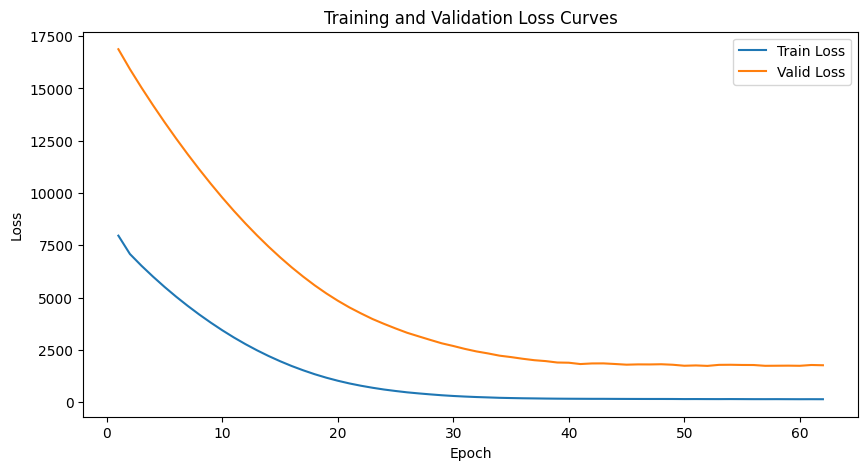

In [46]:
# Step 6: Visualization
# Loss Curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses)+1), train_losses, label='Train Loss')
plt.plot(range(1, len(valid_losses)+1), valid_losses, label='Valid Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()


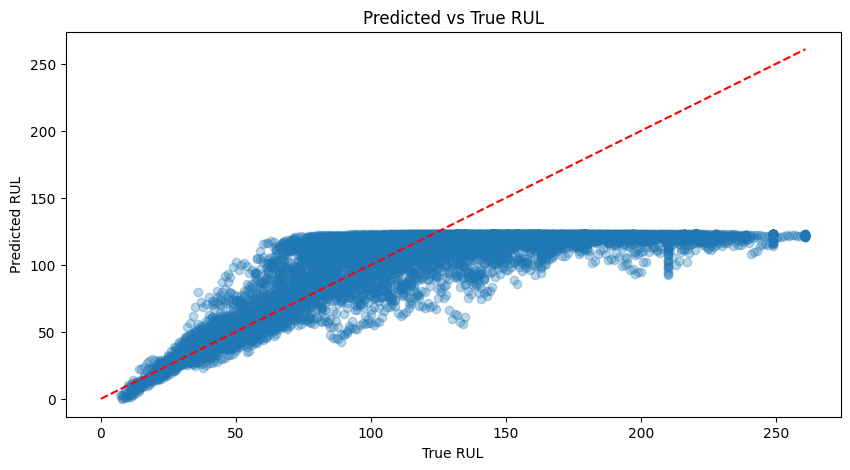

In [47]:
# Scatter Plot
plt.figure(figsize=(10, 5))
plt.scatter(y_valid, y_pred, alpha=0.3)
plt.plot([0, max(y_valid)], [0, max(y_valid)], 'r--')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Predicted vs True RUL')
plt.show()



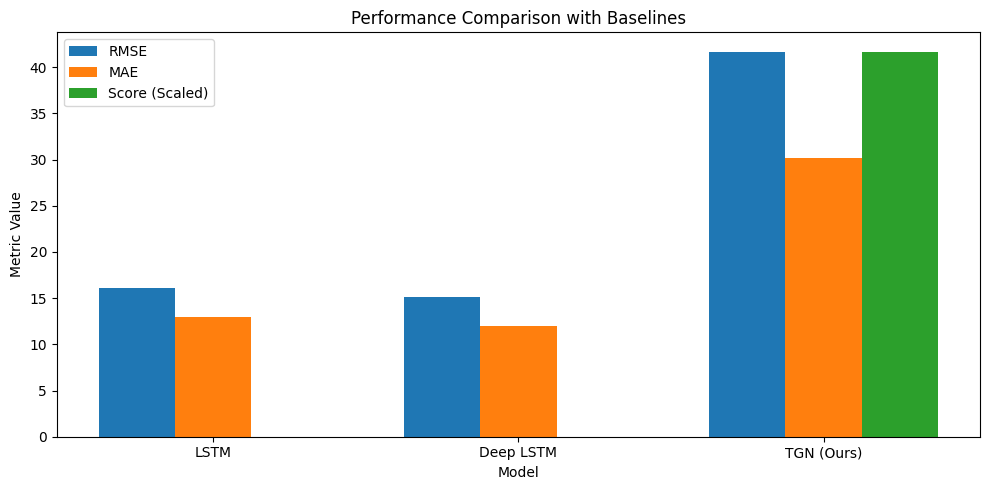

In [48]:
# Bar Chart with Baselines
baselines = {
    'LSTM': {'RMSE': 16.14, 'MAE': 13.00, 'Score': 595.0},
    'Deep LSTM': {'RMSE': 15.10, 'MAE': 12.00, 'Score': 550.0},
    'TGN (Ours)': {'RMSE': rmse, 'MAE': mae, 'Score': score}
}

chart_data = {
    'Model': baselines.keys(),
    'RMSE': [metrics['RMSE'] for metrics in baselines.values()],
    'MAE': [metrics['MAE'] for metrics in baselines.values()],
    'Score': [metrics['Score'] for metrics in baselines.values()]
}
chart_df = pd.DataFrame(chart_data)

fig, ax = plt.subplots(figsize=(10, 5))
bar_width = 0.25
index = np.arange(len(chart_data['Model']))
ax.bar(index, chart_df['RMSE'], bar_width, label='RMSE', color='#1f77b4')
ax.bar(index + bar_width, chart_df['MAE'], bar_width, label='MAE', color='#ff7f0e')
ax.bar(index + 2 * bar_width, chart_df['Score'] / max(chart_df['Score']) * max(chart_df['RMSE']), bar_width, label='Score (Scaled)', color='#2ca02c')
ax.set_xlabel('Model')
ax.set_ylabel('Metric Value')
ax.set_title('Performance Comparison with Baselines')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(chart_data['Model'])
ax.legend()
plt.tight_layout()
plt.show()

In [49]:
# Chart.js configuration
chart_config = {
    "type": "bar",
    "data": {
        "labels": list(chart_data['Model']),
        "datasets": [
            {
                "label": "RMSE",
                "data": chart_df['RMSE'].tolist(),
                "backgroundColor": "#1f77b4",
                "borderColor": "#1f77b4",
                "borderWidth": 1
            },
            {
                "label": "MAE",
                "data": chart_df['MAE'].tolist(),
                "backgroundColor": "#ff7f0e",
                "borderColor": "#ff7f0e",
                "borderWidth": 1
            },
            {
                "label": "Score (Scaled)",
                "data": (chart_df['Score'] / max(chart_df['Score']) * max(chart_df['RMSE'])).tolist(),
                "backgroundColor": "#2ca02c",
                "borderColor": "#2ca02c",
                "borderWidth": 1
            }
        ]
    },
    "options": {
        "scales": {
            "y": {
                "beginAtZero": True,
                "title": {
                    "display": True,
                    "text": "Metric Value"
                }
            },
            "x": {
                "title": {
                    "display": True,
                    "text": "Model"
                }
            }
        },
        "plugins": {
            "legend": {
                "display": True
            },
            "title": {
                "display": True,
                "text": "Performance Comparison with Baselines"
            }
        }
    }
}
print("Chart.js configuration for interactive bar chart:")
print(chart_config)

Chart.js configuration for interactive bar chart:
{'type': 'bar', 'data': {'labels': ['LSTM', 'Deep LSTM', 'TGN (Ours)'], 'datasets': [{'label': 'RMSE', 'data': [16.14, 15.1, 41.68901386400409], 'backgroundColor': '#1f77b4', 'borderColor': '#1f77b4', 'borderWidth': 1}, {'label': 'MAE', 'data': [13.0, 12.0, 30.144746780395508], 'backgroundColor': '#ff7f0e', 'borderColor': '#ff7f0e', 'borderWidth': 1}, {'label': 'Score (Scaled)', 'data': [0.004524216632522797, 0.004182048988046283, 41.68901386400409], 'backgroundColor': '#2ca02c', 'borderColor': '#2ca02c', 'borderWidth': 1}]}, 'options': {'scales': {'y': {'beginAtZero': True, 'title': {'display': True, 'text': 'Metric Value'}}, 'x': {'title': {'display': True, 'text': 'Model'}}}, 'plugins': {'legend': {'display': True}, 'title': {'display': True, 'text': 'Performance Comparison with Baselines'}}}}
